In [1]:
import truststore

# Use the computer's trusted certificates
truststore.inject_into_ssl()

In [40]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

RANDOM_STATE = 42

## 1. Get & understand the data

In [3]:
df = sns.load_dataset("titanic")  # load the titanic data from seaborn
df.head() 

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.shape  # size of data (rows, columns)

(891, 15)

In [5]:
df.info()  # column types and missing values

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [6]:
df.describe()  # summary of the number columns

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df["survived"].value_counts()  # how many died (0) and survived (1)

survived
0    549
1    342
Name: count, dtype: int64

In [8]:
df["survived"].value_counts(normalize=True)  # same counts as percentages

survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [9]:
df["survived"].value_counts(normalize=True)  # same counts as percentages

survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

## 2. Explore & clean the data

In [10]:
df.isnull().sum()  # missing values per column

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [11]:
df.duplicated().sum()  # number of duplicate rows

np.int64(107)

In [12]:
df[df["fare"] == 0].shape[0]  # passengers with a fare of 0 (unusual value)

15

In [13]:
df[["sex", "embarked", "pclass"]].nunique()  # how many categories in each categorical column

sex         2
embarked    3
pclass      3
dtype: int64

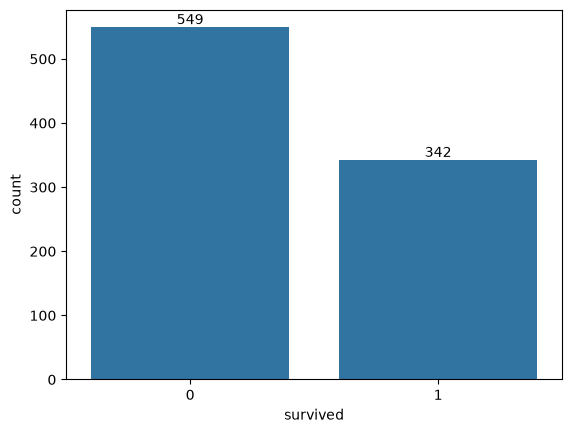

In [14]:
ax = sns.countplot(x="survived", data=df)  # class balance: died vs survived
ax.bar_label(ax.containers[0])  # write the count on top of each bar
plt.show()

In [15]:
df = df.drop(columns=["deck", "alive", "embark_town", "class"])  # deck has too many gaps, the other 3 repeat other columns

In [16]:
#df["age"] = df["age"].fillna(df["age"].median())  # fill gaps with the median age
#df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])  # fillgaps with the most common port

## Keep missing values until after the train/test split
# Fill them using training data only to avoid learning from the test set

In [17]:
df.isnull().sum()  # final checks

survived        0
pclass          0
sex             0
age           177
sibsp           0
parch           0
fare            0
embarked        2
who             0
adult_male      0
alone           0
dtype: int64

## 3. Choose X and y variables

In [18]:
y = df["survived"]  # what we want to predict

In [19]:
X = df[["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]  # inputs the model learns from

## 4. Check initial logistic regression assumptions

In [20]:
y.unique()  # checking binary target

array([0, 1])

In [21]:
X.shape  # sample size

(891, 7)

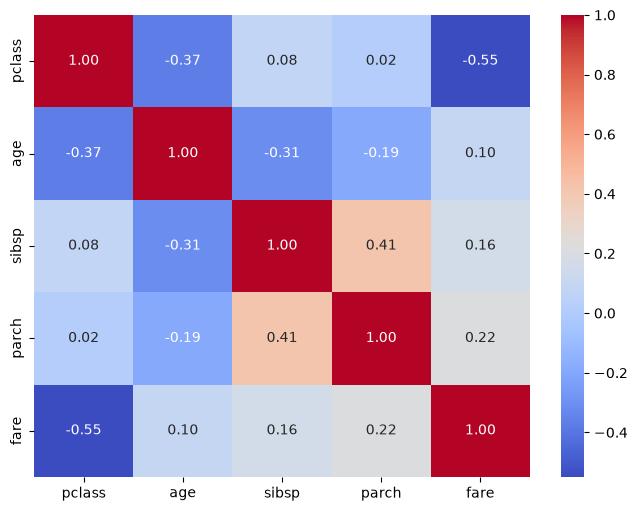

In [22]:
plt.figure(figsize=(8, 6))

# Check correlations between numeric inputs only
sns.heatmap(
    X.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

- The strongest correlation is between passenger class and fare (-0.55)
- Higher-class passengers (lower pclass numbers) generally paid higher fares

- sibsp and parch have a moderate positive correlation (0.41)

- Passengers travelling with siblings or spouses may also travel with parents or children

- No pair shows a very strong correlation, so keep these inputs for now

- This is an initial check; it does not rule out multicollinearity

Text columns such as sex and embarked cannot be used in this correlation calculation

We will encode these columns before training the model

## 5. Split into training & test data

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)  # 80% train, 20% test, stratify keeps the died/survived ratio the same in both

In [24]:
print(X_train.shape, X_test.shape)  # rows and columns in train and test

(712, 7) (179, 7)


In [25]:
print(y_train.value_counts(normalize=True))  # died/survived % in train
print(y_test.value_counts(normalize=True))  # died/survived % in test

survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


For sabs info The data was split 80/20 (712 train, 179 test) with stratify, so both sets keep the same 62% died / 38% survived balance.

## 6. Create & train the model

In [26]:
# Separate numeric and categorical inputs
# Treat passenger class as a category
numeric_features = ["age", "sibsp", "parch", "fare"]
categorical_features = ["pclass", "sex", "embarked"]

# Set up missing-value handling and scaling for numeric inputs
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# These steps will learn from training data when we fit the full model

In [27]:
# Fill categorical gaps with the most common training value
# Convert categories into numeric columns
# Leave out one category per input to use as a reference
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

# Combine preparation for numeric and categorical inputs
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [28]:
# Combine data preparation with logistic regression
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# Learn missing-value replacements, scaling and model coefficients
# Use training data only
model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


Model training summary
We prepared the passenger information by filling missing values, converting categories into numbers and putting numeric inputs on a comparable scale.

We then trained logistic regression to learn patterns linked to survival, using only the 712 training passengers. The 179 test passengers remain separate so we can check how well the model predicts unseen outcomes.

## 7. Make predictions

In [29]:
# Predict survival outcomes: 0 = did not survive, 1 = survived
y_pred = model.predict(X_test)

# Get the predicted probability of survival
y_prob = model.predict_proba(X_test)[:, 1]

# Compare actual outcomes with predictions for the first 10 test passengers
predictions = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Survival probability": y_prob
})

predictions.head(10)

,Actual,Predicted,Survival probability
565,0,0,0.072060
160,0,0,0.052313
553,1,0,0.165954
860,0,0,0.039000
241,1,1,0.666834
559,1,0,0.441149
387,1,1,0.764636
536,0,0,0.290774
698,0,0,0.349791
99,0,0,0.185699


For these first 10 passengers, 8 predictions are correct. Passengers 553 and 559 survived, but their predicted probabilities were below 0.5, so the model classified them as not surviving. We need all 179 test passengers to assess overall performance.

## 8. Evaluate model performance

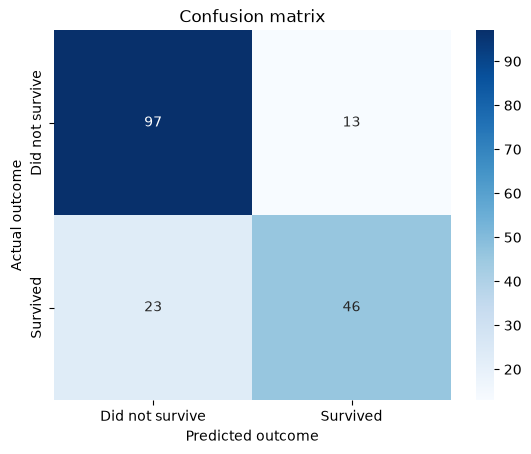

In [30]:
# Count correct and incorrect predictions across all test passengers
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Show actual outcomes against predicted outcomes
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did not survive", "Survived"],
    yticklabels=["Did not survive", "Survived"]
)

plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.title("Confusion matrix")
plt.show()

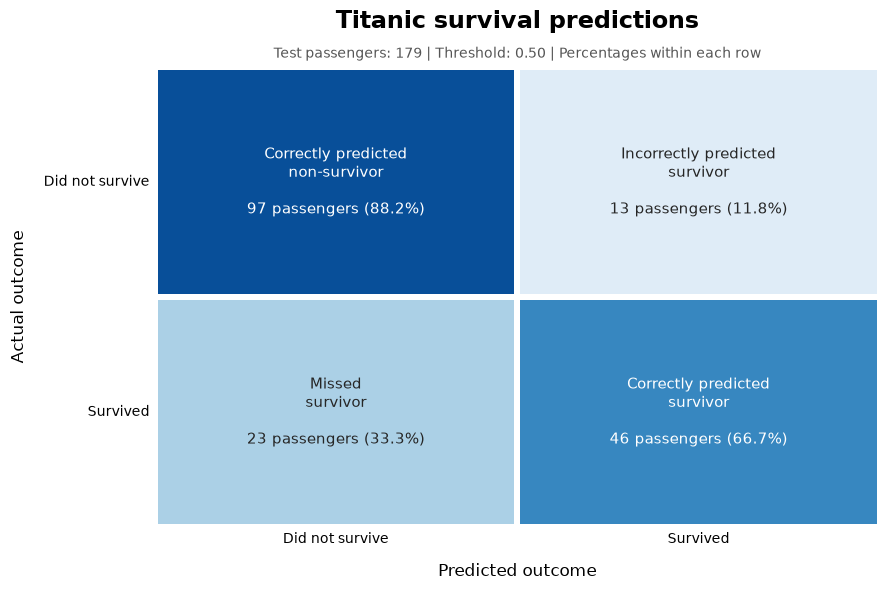

In [31]:
# Count correct and incorrect predictions
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Calculate percentages within each actual outcome
row_percentages = cm / cm.sum(axis=1, keepdims=True) * 100

# Explain what each box represents
descriptions = np.array([
    ["Correctly predicted\nnon-survivor", "Incorrectly predicted\nsurvivor"],
    ["Missed\nsurvivor", "Correctly predicted\nsurvivor"]
])

# Combine descriptions, counts and percentages
labels = np.array([
    f"{description}\n\n{count} passengers ({percentage:.1f}%)"
    for description, count, percentage in zip(
        descriptions.flatten(), cm.flatten(), row_percentages.flatten()
    )
]).reshape(2, 2)

# Use colour to show percentages within each actual outcome
fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    row_percentages,
    annot=labels,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar=False,
    linewidths=3,
    linecolor="white",
    annot_kws={"fontsize": 11},
    xticklabels=["Did not survive", "Survived"],
    yticklabels=["Did not survive", "Survived"],
    ax=ax
)

ax.set_title(
    "Titanic survival predictions",
    fontsize=17,
    fontweight="bold",
    pad=28
)
ax.text(
    0.5, 1.02,
    f"Test passengers: {cm.sum()} | Threshold: 0.50 | Percentages within each row",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#555555"
)

ax.set_xlabel("Predicted outcome", fontsize=12, labelpad=12)
ax.set_ylabel("Actual outcome", fontsize=12, labelpad=12)
ax.tick_params(axis="both", length=0)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

The model correctly classified **143 of 179 passengers (79.9%)**.
It identified **88.2% of non-survivors** and **66.7% of survivors**,
so it was better at identifying non-survivors. It missed 23 survivors
and incorrectly predicted survival for 13 non-survivors.

Calculating the performance scores:

In [32]:
# Treat survived (1) as the positive outcome
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    "Meaning": [
        "Share of all passengers classified correctly",
        "Of predicted survivors, how many actually survived",
        "Of actual survivors, how many the model identified",
        "A combined measure of precision and recall"
    ]
})

# Display scores as percentages
metrics.style.format({"Score": "{:.1%}"}).hide(axis="index")

Metric,Score,Meaning
Accuracy,79.9%,Share of all passengers classified correctly
Precision,78.0%,"Of predicted survivors, how many actually survived"
Recall,66.7%,"Of actual survivors, how many the model identified"
F1 score,71.9%,A combined measure of precision and recall


The model correctly classified **79.9%** of test passengers.
Of those predicted to survive, **78.0%** actually survived.
However, it identified only **66.7%** of actual survivors, missing one-third.
The **71.9% F1 score** reflects the balance between precision and recall.

### ROC/AUC

An ROC curve (Receiver Operating Characteristic curve) and its summary AUC (Area Under the Curve) measure how well a binary classification model separates positive and negative classes across all possible decision thresholds

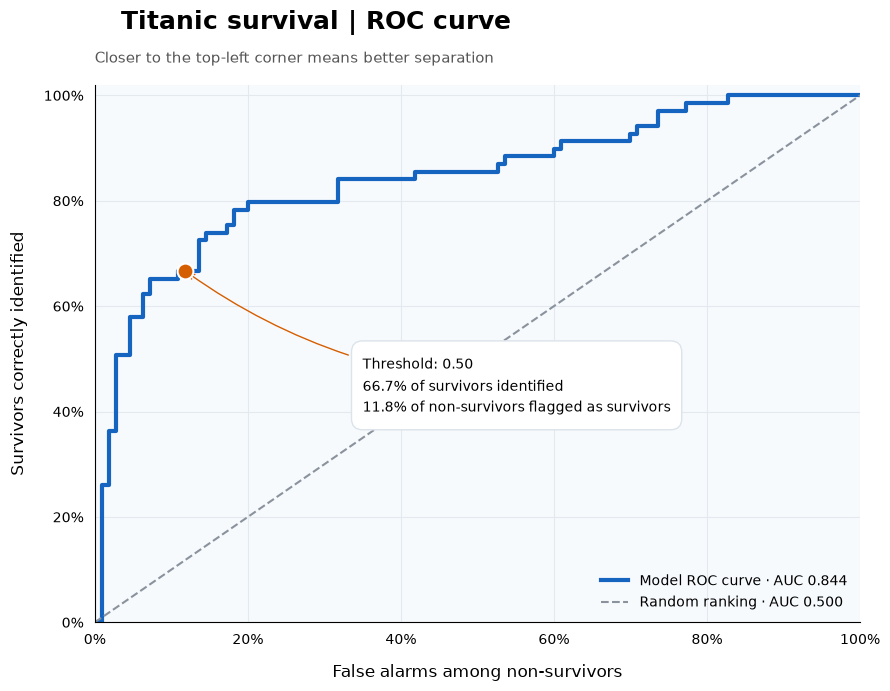

In [33]:
# Calculate performance across different probability thresholds
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate performance at the current 0.50 threshold
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
current_fpr = fp / (fp + tn)
current_tpr = tp / (tp + fn)

# Create a clean chart with space for labels
fig, ax = plt.subplots(figsize=(9, 7))
ax.set_facecolor("#F7FAFD")

# Plot the ROC curve
ax.plot(
    fpr, tpr,
    color="#1565C0",
    linewidth=3,
    label=f"Model ROC curve · AUC {auc:.3f}"
)

# Show the reference line for random ranking
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="#8A939D",
    linewidth=1.5,
    label="Random ranking · AUC 0.500"
)

# Highlight the current threshold
ax.scatter(
    current_fpr, current_tpr,
    color="#D55E00",
    edgecolor="white",
    linewidth=1.5,
    s=130,
    zorder=5
)

# Explain the highlighted point
ax.annotate(
    f"Threshold: 0.50\n"
    f"{current_tpr:.1%} of survivors identified\n"
    f"{current_fpr:.1%} of non-survivors flagged as survivors",
    xy=(current_fpr, current_tpr),
    xytext=(0.35, 0.40),
    fontsize=10,
    linespacing=1.6,
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="white",
        edgecolor="#DCE3EB"
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="#D55E00",
        connectionstyle="arc3,rad=-0.15"
    )
)

# Use a title and subtitle to explain the chart
fig.suptitle(
    "Titanic survival | ROC curve",
    fontsize=18,
    fontweight="bold",
    x=0.14,
    ha="left"
)
ax.set_title(
    "Closer to the top-left corner means better separation",
    fontsize=11,
    color="#555555",
    loc="left",
    pad=16
)

# Show rates as percentages
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xticks(np.linspace(0, 1, 6))
ax.set_yticks(np.linspace(0, 1, 6))

ax.set_xlabel("False alarms among non-survivors", fontsize=12, labelpad=12)
ax.set_ylabel("Survivors correctly identified", fontsize=12, labelpad=12)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(color="#E3E9EF", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False, fontsize=10)
ax.tick_params(axis="both", length=0, pad=8)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

The model achieved an **AUC of 0.844**, showing better separation between
survivors and non-survivors than random ranking (0.500).

At the **0.50 threshold**, it identified **66.7% of survivors** and incorrectly
classified **11.8% of non-survivors** as survivors. Lowering the threshold
would generally identify more survivors, but also increase false alarms.

## 9. Check model diagnostics & remaining assumptions

In [34]:
# Check how many iterations the model used during training
classifier = model.named_steps["classifier"]

iterations_used = classifier.n_iter_[0]
iteration_limit = classifier.max_iter

print(f"Iterations used: {iterations_used}")
print(f"Iteration limit: {iteration_limit}")

# Reaching the limit may mean the model needs more iterations
print(f"Reached iteration limit: {iterations_used >= iteration_limit}")

Iterations used: 16
Iteration limit: 1000
Reached iteration limit: False


In [35]:
# Check that the model finished learning before reaching its iteration limit
# It stopped after 16 of the allowed 1,000 iterations
# With no convergence warning, this indicates training converged
# This checks training stability, not prediction accuracy

Next check multicollinearity—whether inputs overlap enough to make their individual effects difficult to interpret.

In [36]:
# Get the prepared training inputs used by the model
prepared = model.named_steps["preprocessor"]
X_prepared = prepared.transform(X_train)

# Convert sparse output to a regular array if needed
if hasattr(X_prepared, "toarray"):
    X_prepared = X_prepared.toarray()

X_diagnostics = pd.DataFrame(
    X_prepared,
    columns=prepared.get_feature_names_out()
)

# Calculate VIF by predicting each input from all the other inputs
vif_values = []

for column in X_diagnostics.columns:
    other_inputs = X_diagnostics.drop(columns=column)
    current_input = X_diagnostics[column]

    r_squared = LinearRegression().fit(
        other_inputs, current_input
    ).score(other_inputs, current_input)

    vif_values.append(
        1 / (1 - r_squared) if r_squared < 1 else np.inf
    )

# Higher VIF means more overlap with other inputs
vif_table = pd.DataFrame({
    "Feature": X_diagnostics.columns,
    "VIF": vif_values
}).sort_values("VIF", ascending=False)

vif_table.round(2)

,Feature,VIF
5,categorical__pclass_3,2.80
4,categorical__pclass_2,2.13
3,numeric__fare,1.76
8,categorical__embarked_S,1.50
7,categorical__embarked_Q,1.46
2,numeric__parch,1.31
1,numeric__sibsp,1.26
0,numeric__age,1.20
6,categorical__sex_male,1.15


All VIF values are below 5, ranging from **1.15 to 2.80**, so this check
shows no substantial multicollinearity concern. We will retain all inputs.

Passenger-class categories have the highest VIF values, but these remain
within an acceptable range.

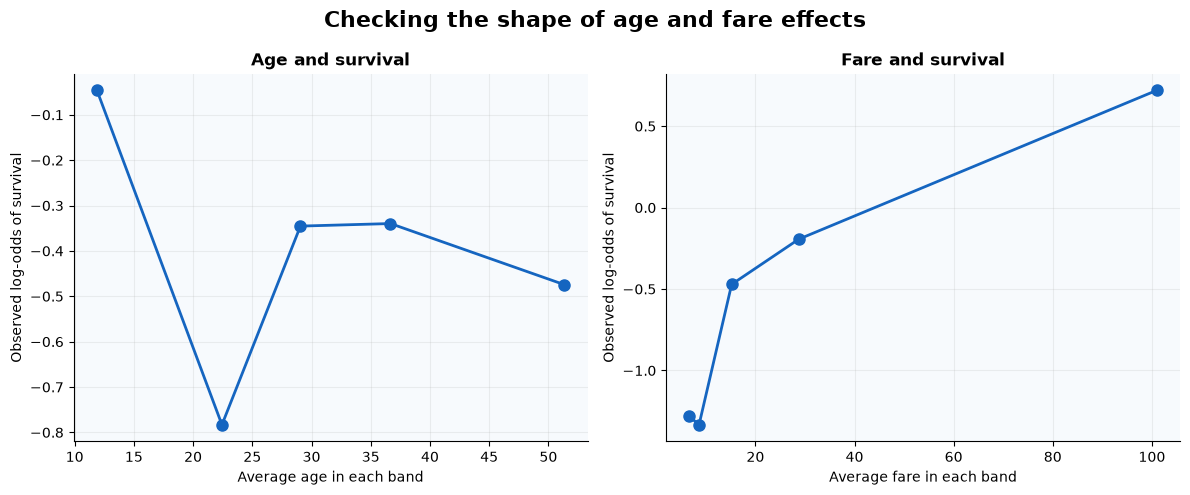

In [37]:
# Combine training inputs with their actual survival outcomes
training_data = X_train.copy()
training_data["survived"] = y_train

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature in zip(axes, ["age", "fare"]):

    # Use known values and group passengers into five bands
    data = training_data[[feature, "survived"]].dropna().copy()
    data["band"] = pd.qcut(data[feature], q=5, duplicates="drop")

    # Calculate the average input and survival counts in each band
    grouped = data.groupby("band", observed=True).agg(
        average=(feature, "mean"),
        survivors=("survived", "sum"),
        passengers=("survived", "count")
    )

    # Calculate observed log-odds
    # Adding 0.5 avoids undefined values if a band has no survivors or deaths
    grouped["log_odds"] = np.log(
        (grouped["survivors"] + 0.5)
        / (grouped["passengers"] - grouped["survivors"] + 0.5)
    )

    # Look for a roughly straight pattern across the bands
    ax.plot(
        grouped["average"], grouped["log_odds"],
        marker="o", markersize=8,
        linewidth=2, color="#1565C0"
    )

    ax.set_title(f"{feature.title()} and survival", fontweight="bold")
    ax.set_xlabel(f"Average {feature} in each band")
    ax.set_ylabel("Observed log-odds of survival")
    ax.set_facecolor("#F7FAFD")
    ax.grid(alpha=0.2)
    sns.despine(ax=ax)

fig.suptitle(
    "Checking the shape of age and fare effects",
    fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.show()

### Age and fare: diagnostic takeaway

Age shows an uneven relationship with survival log-odds. Fare generally
increases with survival log-odds, although the pattern has some bends.

These graphs show each variable separately and do not account for the
other inputs, so they cannot confirm the linearity assumption.

We’ll use a Box–Tidwell check, which tests whether age and fare need a nonlinear effect on the log-odds.

In [38]:
import statsmodels.api as sm

# Use training passengers with known, positive age and fare
# Logarithms require positive values
valid = (
    X_train["age"].notna()
    & (X_train["age"] > 0)
    & (X_train["fare"] > 0)
)

# Keep the other prepared inputs to account for their effects
X_linearity = X_diagnostics.loc[valid.to_numpy()].copy()

# Add terms that test departures from a linear effect
for feature in ["age", "fare"]:
    values = X_train.loc[valid, feature].to_numpy()
    X_linearity[f"{feature}_log"] = values * np.log(values)

# Fit a separate logistic model for this diagnostic
# This does not replace our prediction model
diagnostic_model = sm.GLM(
    y_train.loc[valid].to_numpy(),
    sm.add_constant(X_linearity),
    family=sm.families.Binomial()
).fit()

# Show the test results for age and fare
linearity_results = pd.DataFrame({
    "Feature": ["age", "fare"],
    "P-value": diagnostic_model.pvalues[
        ["age_log", "fare_log"]
    ].to_numpy()
})

print(f"Training passengers checked: {valid.sum()}")
linearity_results.round(4)

Training passengers checked: 569


,Feature,P-value
0,age,0.0051
1,fare,0.9136


### Statistical check: age and fare

After accounting for the other inputs:

- **Age (p = 0.0051):** Below the 0.025 cutoff, suggesting a nonlinear
  effect. Test a more flexible age effect in task 10.
- **Fare (p = 0.9136):** No evidence of nonlinearity from this test.
  Keep its current form for now.

The test used **569 training passengers** with known age and positive fare.

Next, we’ll check for overfitting—whether the model performs much better on passengers it learned from than on unseen passengers.

In [41]:
# Divide training data into five parts with similar survival proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Train on four parts and validate on the remaining part
# Repeat five times, learning preprocessing within each fold
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "auc": "roc_auc"},
    return_train_score=True
)

# Compare average training and validation performance
cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "ROC AUC"],
    "Training mean": [
        cv_results["train_accuracy"].mean(),
        cv_results["train_auc"].mean()
    ],
    "Validation mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_auc"].mean()
    ]
})

cv_summary.round(3)

,Metric,Training mean,Validation mean
0,Accuracy,0.808,0.802
1,ROC AUC,0.860,0.853


### Overfitting check

Training and validation performance were similar:

- **Accuracy:** 80.8% during training versus 80.2% during validation.
- **ROC AUC:** 0.860 during training versus 0.853 during validation.

These small gaps suggest no substantial overfitting in this check.
The model performed consistently across the training and validation data.

### Passenger independence

Passengers travelling together may share survival outcomes, so complete
independence cannot be assumed. This dataset lacks family and ticket
identifiers needed to reliably keep travel groups together during splitting.

Matching passenger details do not necessarily mean duplicate records,
so we retained those rows. Random splitting may therefore give an optimistic
estimate of performance for entirely new travel groups.

## 10. Interpret, improve & retest the model